# Laboratorio Dry Bean Dataset

## CRISP-DM + TDSP + Scrum ML

### Objetivo
Construir y evaluar modelos de clasificación para predecir la variedad de frijol seco a partir de características geométricas, siguiendo una metodología reproducible de ciencia de datos.


## 1. Comprensión del negocio — CRISP-DM (revisión académica)

**Caso simulado:** una empresa agrícola desea apoyar la identificación de siete variedades de frijol para su control de calidad. Parte de su proceso es manual, pero no contamos con mediciones reales de tiempo, error humano o costos.

**Problema empresarial:** explorar la clasificación automática como apoyo a una tarea agrícola.

**Problema técnico:** clasificación multiclase de `Class` usando 16 medidas geométricas tabulares (no imágenes en bruto).

**Evaluación del prototipo:** comparación de regresión logística (baseline) y Random Forest, priorizando F1 macro, usando Accuracy y matriz de confusión como complementos. No se han definido umbrales de negocio ni se ha evaluado rendimiento en campo.

**Usuarios potenciales:** operadores o responsables de clasificación de una empresa agrícola hipotética. No se realizaron entrevistas.

Documento de soporte: `docs/crisp_dm/01_comprension_negocio.md`.


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib
from pathlib import Path

# La ruta raíz se identifica a partir de los archivos del proyecto, no del SO.
def encontrar_raiz_proyecto():
    ubicacion = Path.cwd().resolve()
    for carpeta in (ubicacion, *ubicacion.parents):
        if (carpeta / "requirements.txt").is_file() and (carpeta / "src" / "predict.py").is_file():
            return carpeta
    raise FileNotFoundError("Abre Jupyter desde la carpeta del laboratorio para localizar el proyecto")


In [5]:

# Descargar dataset Dry Bean desde UCI
dry_bean = fetch_ucirepo(id=602)

# Separar variables predictoras y objetivo
X = dry_bean.data.features
y = dry_bean.data.targets

# Unir los datos
df = pd.concat([X, y], axis=1)

# Mostrar las primeras cinco filas
df.head()


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



## Actividad 1 - Comprensión inicial de los datos

1. ¿Cuántas columnas tiene el dataset?
2. ¿Cuál es la variable objetivo?
3. ¿El problema es de clasificación o regresión?


In [6]:

print("Dimensiones del dataset:", df.shape)

print("Número de columnas:", df.shape[1])

print("Variable objetivo: Class")

print("Clases disponibles:")
print(df["Class"].unique())


Dimensiones del dataset: (13611, 17)
Número de columnas: 17
Variable objetivo: Class
Clases disponibles:
['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']


## 2. Comprensión de los datos - CRISP-DM

En esta fase analizamos la estructura, características y calidad del
Dry Bean Dataset antes de preparar los datos para el entrenamiento.

In [7]:
# Dimensiones del dataset
print("Dimensiones:", df.shape)

# Información de las columnas
df.info()

# Estadísticas descriptivas
df.describe()

Dimensiones: (13611, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [8]:
# Revisar valores faltantes
missing_values = df.isna().sum()

# Revisar filas duplicadas
duplicated_rows = df.duplicated().sum()

print("VALORES NULOS POR COLUMNA:")
print(missing_values)

print("\nTOTAL DE FILAS DUPLICADAS:")
print(duplicated_rows)

VALORES NULOS POR COLUMNA:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRatio        0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
Roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

TOTAL DE FILAS DUPLICADAS:
68


## 3. Análisis de la variable objetivo

La variable objetivo es Class, que contiene la variedad
de fríjol que el modelo deberá aprender a clasificar.

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


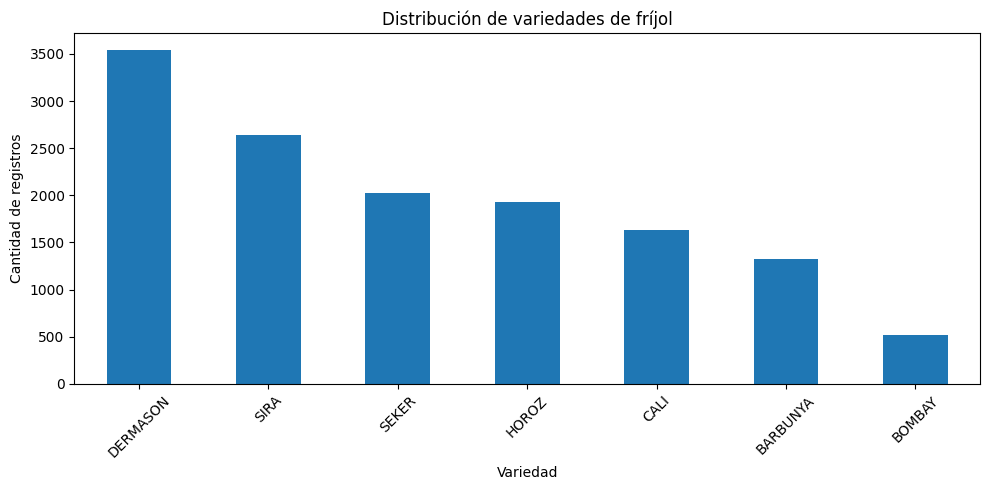

In [9]:
# Contar registros por variedad
class_counts = df["Class"].value_counts()

print(class_counts)

# Crear gráfico
class_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Distribución de variedades de fríjol")
plt.xlabel("Variedad")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Preparación de los datos - CRISP-DM

En esta fase se revisan las observaciones duplicadas y se preparan
las variables para el entrenamiento de los modelos de clasificación.

In [10]:
# Crear una copia para preservar los datos originales
df_clean = df.copy()

# Contar duplicados antes de limpiar
duplicados_antes = df_clean.duplicated().sum()

# Eliminar filas idénticas
df_clean = df_clean.drop_duplicates()

print("Duplicados encontrados:", duplicados_antes)
print("Registros después de limpieza:", len(df_clean))
print("Dimensiones finales:", df_clean.shape)

Duplicados encontrados: 68
Registros después de limpieza: 13543
Dimensiones finales: (13543, 17)


In [11]:
# X contiene las 16 características de los fríjoles
X = df_clean.drop(columns="Class")

# y contiene la variedad que queremos predecir
y = df_clean["Class"]

print("Variables predictoras:", X.shape)
print("Variable objetivo:", y.shape)

Variables predictoras: (13543, 16)
Variable objetivo: (13543,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))
print("Total:", len(X_train) + len(X_test))

Registros de entrenamiento: 10834
Registros de prueba: 2709
Total: 13543


In [13]:
from pathlib import Path

# Buscar la raíz del proyecto
proyecto = encontrar_raiz_proyecto()

ruta_salida = proyecto / "data" / "processed"
ruta_salida.mkdir(parents=True, exist_ok=True)

# Guardar los datos limpios
df_clean.to_csv(
    ruta_salida / "drybean_clean.csv",
    index=False
)

print("Datos limpios guardados en:", ruta_salida)

Datos limpios guardados en: [RUTA_LOCAL_ORIGINAL]/laboratorio_drybean_ml/data/processed



## 5. Modelado - CRISP-DM

### Modelo baseline: Regresión Logística

Se implementa un modelo de regresión logística multiclase como punto de referencia para evaluar la clasificación de variedades de fríjol.

El modelo permitirá establecer un desempeño inicial que posteriormente será comparado con Random Forest.

Para el entrenamiento se utiliza un pipeline que combina la estandarización de las variables numéricas con el algoritmo de clasificación.


In [14]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Crear modelo baseline
baseline_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Entrenar modelo
baseline_model.fit(X_train, y_train)

print("Modelo Logistic Regression entrenado correctamente")


Modelo Logistic Regression entrenado correctamente


[RUTA_LOCAL_ORIGINAL]/laboratorio_drybean_ml/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
[RUTA_LOCAL_ORIGINAL]/laboratorio_drybean_ml/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
[RUTA_LOCAL_ORIGINAL]/laboratorio_drybean_ml/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
[RUTA_LOCAL_ORIGINAL]/laboratorio_drybean_ml/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointwise.T @ X + l2_reg_strength * weights
[RUTA_

In [15]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Hacer predicciones
y_pred_baseline = baseline_model.predict(X_test)

# Calcular métricas
accuracy_baseline = accuracy_score(
    y_test, y_pred_baseline
)

f1_baseline = f1_score(
    y_test,
    y_pred_baseline,
    average="macro"
)

print("Accuracy baseline:", accuracy_baseline)
print("F1 macro baseline:", f1_baseline)

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_baseline))


Accuracy baseline: 0.9195275009228497
F1 macro baseline: 0.9305508722243493

Reporte de clasificación:
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.89      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



[RUTA_LOCAL_ORIGINAL]/laboratorio_drybean_ml/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
[RUTA_LOCAL_ORIGINAL]/laboratorio_drybean_ml/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
[RUTA_LOCAL_ORIGINAL]/laboratorio_drybean_ml/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b



## 6. Modelo alternativo: Random Forest

Se implementa un modelo Random Forest para comparar su desempeño con la regresión logística.

Random Forest combina múltiples árboles de decisión para identificar patrones y clasificar las variedades de fríjol.

Se utilizarán 200 árboles de decisión y una semilla fija para garantizar la reproducibilidad del experimento.


In [16]:

from sklearn.ensemble import RandomForestClassifier

# Crear modelo Random Forest
forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Entrenar el modelo
forest_model.fit(X_train, y_train)

print("Modelo Random Forest entrenado correctamente")


Modelo Random Forest entrenado correctamente


In [17]:

# Realizar predicciones
y_pred_forest = forest_model.predict(X_test)

# Calcular métricas
accuracy_forest = accuracy_score(
    y_test,
    y_pred_forest
)

f1_forest = f1_score(
    y_test,
    y_pred_forest,
    average="macro"
)

print("Accuracy Random Forest:", accuracy_forest)
print("F1 macro Random Forest:", f1_forest)

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_forest))


Accuracy Random Forest: 0.9180509413067552
F1 macro Random Forest: 0.9292100000398094

Reporte de clasificación:
              precision    recall  f1-score   support

    BARBUNYA       0.92      0.89      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.93      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.94      0.95      0.95       406
        SIRA       0.87      0.85      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709




## 7. Comparación de modelos

Se comparan los resultados obtenidos por Logistic Regression y Random Forest utilizando las métricas Accuracy y F1 macro.

El objetivo es identificar qué algoritmo presenta mejor desempeño en la clasificación de las siete variedades de fríjol.


In [18]:

# Crear tabla comparativa
results = pd.DataFrame({
    "Modelo": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_baseline,
        accuracy_forest
    ],
    "F1 Macro": [
        f1_baseline,
        f1_forest
    ]
})

# Mostrar tabla
display(results.round(4))


,Modelo,Accuracy,F1 Macro
0,Logistic Regression,0.9195,0.9306
1,Random Forest,0.9181,0.9292



### Interpretación de resultados

Se entrenaron y evaluaron dos modelos de clasificación: Logistic Regression y Random Forest.

Logistic Regression obtuvo un Accuracy de 91,95 % y un F1 Macro de 93,06 %, mientras que Random Forest alcanzó un Accuracy de 91,81 % y un F1 Macro de 92,92 %.

Los resultados muestran un desempeño muy similar entre ambos algoritmos. Sin embargo, Logistic Regression presentó una ligera ventaja en las dos métricas evaluadas.

Considerando el criterio de priorizar F1 Macro y favorecer modelos más sencillos cuando sus resultados son similares, se selecciona provisionalmente Logistic Regression como modelo candidato.

La selección definitiva se realizará después de analizar la matriz de confusión y los errores por clase.


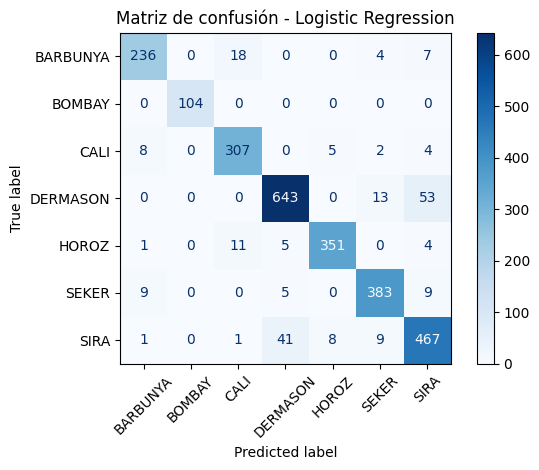

In [19]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseline,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Matriz de confusión - Logistic Regression")
plt.tight_layout()
plt.show()


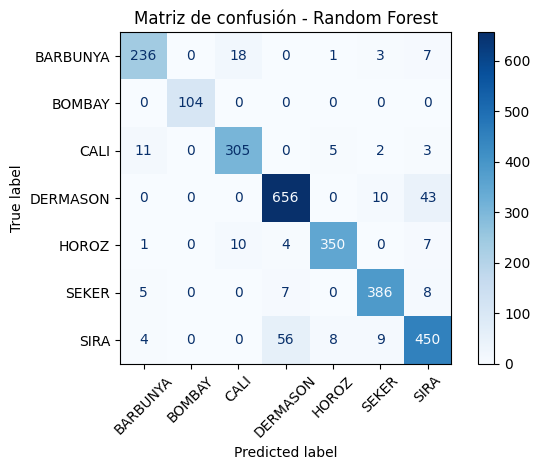

In [20]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_forest,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()
plt.show()


In [21]:

from pathlib import Path

proyecto = encontrar_raiz_proyecto()

ruta_reportes = proyecto / "outputs" / "reports"
ruta_reportes.mkdir(parents=True, exist_ok=True)

for nombre, predicciones in [
    ("logistic_regression", y_pred_baseline),
    ("random_forest", y_pred_forest)
]:
    disp = ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones,
        xticks_rotation=45,
        cmap="Blues"
    )

    disp.ax_.set_title(f"Matriz de confusión - {nombre}")

    disp.figure_.savefig(
        ruta_reportes / f"matriz_{nombre}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(disp.figure_)

print("Matrices guardadas correctamente")


Matrices guardadas correctamente



### Análisis de las matrices de confusión

Se analizaron las matrices de confusión de Logistic Regression y Random Forest, evaluando 2.709 registros de prueba.

Logistic Regression clasificó correctamente 2.491 registros, mientras que Random Forest clasificó correctamente 2.487.

La principal dificultad de ambos modelos se presenta entre las variedades DERMASON y SIRA.

En Logistic Regression se identificaron 94 confusiones entre estas dos clases, mientras que Random Forest presentó 99.

Por otro lado, la variedad BOMBAY fue clasificada correctamente en todos los registros de prueba por ambos modelos.

Las confusiones observadas podrían relacionarse con similitudes geométricas entre algunas variedades, hipótesis que requiere mayor análisis de las características del dataset.

### Selección del modelo

Se selecciona Logistic Regression como modelo candidato para el despliegue local, debido a que obtuvo resultados ligeramente superiores en Accuracy y F1 Macro.

Aunque la diferencia es pequeña, el modelo presenta un desempeño competitivo con menor complejidad que Random Forest en esta configuración.

La decisión corresponde a los resultados obtenidos sobre la partición de prueba utilizada y no garantiza que la ventaja se mantenga en otros conjuntos de datos.


In [22]:

# Importancia de variables de Random Forest
feature_importance = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": forest_model.feature_importances_
})

# Ordenar de mayor a menor importancia
feature_importance = feature_importance.sort_values(
    by="Importancia",
    ascending=False
)

# Mostrar las 10 principales
display(feature_importance.head(10))


,Variable,Importancia
1,Perimeter,0.110709
11,Compactness,0.102704
12,ShapeFactor1,0.101647
14,ShapeFactor3,0.100476
3,MinorAxisLength,0.081581
7,EquivDiameter,0.065696
5,Eccentricity,0.063351
10,Roundness,0.060762
0,Area,0.058652
6,ConvexArea,0.057927


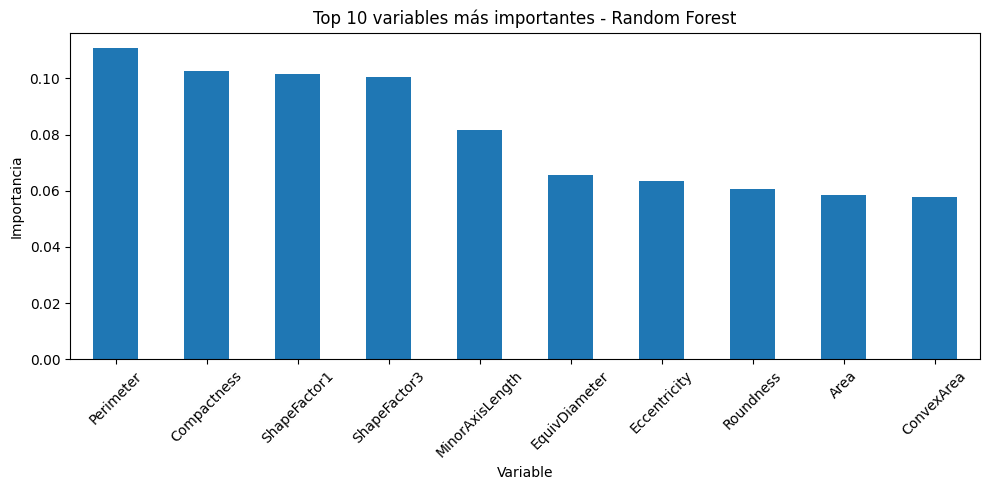

In [23]:

# Visualizar las 10 variables más importantes
feature_importance.head(10).plot(
    x="Variable",
    y="Importancia",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Top 10 variables más importantes - Random Forest")
plt.xlabel("Variable")
plt.ylabel("Importancia")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Interpretación de la importancia de variables

El análisis de importancia de características del modelo Random Forest permitió identificar las variables con mayor contribución a las predicciones.

Las cinco variables más importantes fueron Perimeter (11,07 %), Compactness (10,27 %), ShapeFactor1 (10,16 %), ShapeFactor3 (10,05 %) y MinorAxisLength (8,16 %).

Estas características representan principalmente aspectos geométricos relacionados con el tamaño, la forma y las proporciones de los granos.

Los resultados sugieren que dichas características son relevantes para diferenciar las variedades de fríjol.

Las confusiones observadas entre DERMASON y SIRA podrían estar relacionadas con similitudes en algunas de estas características. Sin embargo, sería necesario realizar un análisis específico por clase para confirmar esta hipótesis.

La importancia de variables obtenida mediante Random Forest indica su utilidad predictiva dentro del modelo entrenado, pero no establece relaciones causales.



## 8. Despliegue local - CRISP-DM

Se realiza una prueba de despliegue local del modelo Logistic Regression.

El objetivo es guardar el modelo entrenado, recuperarlo desde un archivo y utilizarlo para clasificar nuevas observaciones sin necesidad de volver a entrenarlo.


In [24]:

import joblib
from pathlib import Path

# Identificar la carpeta principal del proyecto
proyecto = encontrar_raiz_proyecto()

# Crear directorio de modelos
ruta_modelos = proyecto / "outputs" / "models"
ruta_modelos.mkdir(parents=True, exist_ok=True)

# Guardar el modelo seleccionado
ruta_modelo = ruta_modelos / "logistic_regression_drybean.joblib"

joblib.dump(baseline_model, ruta_modelo)

print("Modelo guardado correctamente en:")
print(ruta_modelo)


Modelo guardado correctamente en:
[RUTA_LOCAL_ORIGINAL]/laboratorio_drybean_ml/outputs/models/logistic_regression_drybean.joblib


In [25]:

# Cargar el modelo guardado
loaded_model = joblib.load(ruta_modelo)

# Seleccionar un registro de prueba
sample = X_test.iloc[[0]]

# Realizar predicción
prediction = loaded_model.predict(sample)

# Comparar resultado
print("Predicción del modelo:", prediction[0])
print("Variedad real:", y_test.iloc[0])


Predicción del modelo: SEKER
Variedad real: SEKER


In [27]:

import sys
from pathlib import Path

proyecto = encontrar_raiz_proyecto()

if str(proyecto) not in sys.path:
    sys.path.insert(0, str(proyecto))

from src.predict import predict_bean_class

sample = X_test.iloc[[0]]

resultado = predict_bean_class(sample)

print("Predicción desde predict.py:", resultado)
print("Variedad real:", y_test.iloc[0])


Predicción desde predict.py: SEKER
Variedad real: SEKER


## 9. Reflexión y límites de la evaluación

- **CRISP-DM:** el problema de negocio justifica por qué se investiga el modelo y las fases permiten construir evidencias.
- **TDSP:** separar datos, notebooks, scripts, resultados y documentos facilita revisión y reproducción.
- **Scrum ML:** las historias, sprints, tablero y retrospectiva ayudan a organizar el trabajo; los nombres/actividades reales deben ser validados por el equipo.
- **Baseline:** sin un punto de referencia sencillo no podemos evaluar si el modelo alternativo aporta una mejora relevante.
- **Métrica de selección:** F1 macro presta atención equivalente a las siete variedades; Accuracy resume los aciertos totales.
- **Errores por clase:** revisar DERMASON/SIRA y posibles solapamientos de medidas antes de proponer cambios.
- **Producción:** esta es una predicción local; faltaría validar con muestras reales, integrar la captura de datos, probar, documentar y monitorear.

La guía de las siete preguntas está en `docs/crisp_dm/03_reflexiones_guia.md`. Las métricas que se ven arriba provienen de las **salidas guardadas del cuaderno original**, no de una nueva ejecución verificada. El entrenamiento original registra avisos numéricos de sklearn que requieren investigación.
